### For Week 4, include concepts such as logistic regression and feature scaling. This homework should be submitted for peer review in the assignment titled 4.3 Peer Review: Week 4 Jupyter Notebook.

Dataset: Lending Club loan data (`adarshsng/lending-club-loan-data-csv`, `loan.csv`). Target is binary loan default, which fits logistic regression. Numeric features span very different scales (loan amount ~ thousands, annual income ~ tens of thousands, interest rate ~ percent), which motivates feature scaling.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                               f1_score, roc_auc_score, confusion_matrix, roc_curve)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

# Lending Club loan data — binary default prediction task
path = kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv")
csv_path = os.path.join(path, "loan.csv")

USECOLS = ['loan_status', 'loan_amnt', 'term', 'int_rate', 'grade',
           'home_ownership', 'annual_inc', 'dti', 'purpose',
           'verification_status', 'open_acc', 'revol_util']
CLOSED = ['Fully Paid', 'Charged Off', 'Default']

chunks = []
for ch in pd.read_csv(csv_path, usecols=USECOLS, chunksize=500000, low_memory=True):
    chunks.append(ch[ch['loan_status'].isin(CLOSED)])
df = pd.concat(chunks, ignore_index=True)

print(f"Closed-loan shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
display(df['loan_status'].value_counts().rename_axis('loan_status').to_frame(name='count'))
display(df.head(3))


Libraries imported successfully.
Closed-loan shape: (1303638, 12)
Columns: ['loan_amnt', 'term', 'int_rate', 'grade', 'home_ownership', 'annual_inc', 'verification_status', 'loan_status', 'purpose', 'dti', 'open_acc', 'revol_util']


,count
loan_status,
Fully Paid,1041952
Charged Off,261655
Default,31


,loan_amnt,term,int_rate,grade,home_ownership,annual_inc,verification_status,loan_status,purpose,dti,open_acc,revol_util
0,30000,36 months,22.35,D,MORTGAGE,100000.0,Source Verified,Fully Paid,debt_consolidation,30.46,11.0,37.0
1,40000,60 months,16.14,C,MORTGAGE,45000.0,Verified,Fully Paid,credit_card,50.53,18.0,64.5
2,20000,36 months,7.56,A,MORTGAGE,100000.0,Not Verified,Fully Paid,credit_card,18.92,9.0,29.9


In [20]:
# Binary target: 1 = default (Charged Off / Default), 0 = repaid (Fully Paid)
df['default'] = df['loan_status'].isin(['Charged Off', 'Default']).astype(int)

# Parse term '36 months' -> 36 (kept as string for one-hot later; numeric copy for inspection)
df['term_months'] = df['term'].str.extract(r'(\d+)').astype(int)

# Keep only modeling columns and drop rows with missing values
df_model = df.dropna(subset=USECOLS).copy().reset_index(drop=True)

print(f"Rows after cleaning: {len(df_model):,}")
print(f"Default rate: {df_model['default'].mean():.4%} ({df_model['default'].sum():,} defaults)")
display(df_model['term'].value_counts().rename_axis('term').to_frame(name='count'))
display(df_model[['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'open_acc', 'revol_util']].describe().round(2))
feature_desc = pd.DataFrame({
    "feature": ["loan_amnt", "int_rate", "annual_inc", "dti", "open_acc", "revol_util"],
    "description": [
        "Principal loan amount requested by the borrower.",
        "Interest rate on the loan, expressed as a percentage.",
        "Borrower's annual income in dollars.",
        "Debt-to-income ratio, measuring monthly debt obligations relative to income.",
        "Number of open credit accounts.",
        "Revolving credit utilization rate, expressed as a percentage of the credit limit used."
    ]
})
pd.set_option("display.max_colwidth", 200)
display(feature_desc)

Rows after cleaning: 1,302,516
Default rate: 20.0732% (261,456 defaults)


,count
term,
36 months,987934
60 months,314582


,loan_amnt,int_rate,annual_inc,dti,open_acc,revol_util
count,1302516.00,1302516.00,1302516.00,1302516.00,1302516.00,1302516.00
mean,14417.84,13.26,76164.24,18.26,11.60,51.91
std,8697.92,4.76,69982.80,10.94,5.46,24.50
min,500.00,5.31,16.00,-1.00,1.00,0.00
25%,8000.00,9.75,45953.00,11.79,8.00,33.60
50%,12000.00,12.74,65000.00,17.61,11.00,52.30
75%,20000.00,15.99,90000.00,24.04,14.00,70.80
max,40000.00,30.99,10999200.00,999.00,90.00,892.30


,feature,description
0,loan_amnt,Principal loan amount requested by the borrower.
1,int_rate,"Interest rate on the loan, expressed as a percentage."
2,annual_inc,Borrower's annual income in dollars.
3,dti,"Debt-to-income ratio, measuring monthly debt obligations relative to income."
4,open_acc,Number of open credit accounts.
5,revol_util,"Revolving credit utilization rate, expressed as a percentage of the credit limit used."


In [21]:
NUM = ['loan_amnt', 'int_rate', 'annual_inc', 'dti', 'open_acc', 'revol_util']
CAT = ['term', 'grade', 'home_ownership', 'purpose', 'verification_status']

# Fixed 60k sample keeps runtime peer-review friendly and reproducible
dfs = df_model.sample(n=min(60000, len(df_model)), random_state=42).reset_index(drop=True)
X = dfs[NUM + CAT]
y = dfs['default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}, test default rate: {y_test.mean():.2%}")
# Explicit decision threshold: predict default when P(default) >= THRESHOLD.
# sklearn .predict() hides this as 0.5; we set it ourselves so it is visible and tunable.
THRESHOLD = 0.50
print(f"Decision threshold THRESHOLD = {THRESHOLD} (explicit, not a hidden default)")
prep_unscaled = ColumnTransformer([
    ('num', 'passthrough', NUM),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT),
])
base_pipe = Pipeline([
    ('prep', prep_unscaled),
    ('clf', LogisticRegression(max_iter=1000)),
])
base_pipe.fit(X_train, y_train)
base_prob = base_pipe.predict_proba(X_test)[:, 1]
base_pred = (base_prob >= THRESHOLD).astype(int)  # explicit 0.50 cutoff

print(f"Unscaled: acc={accuracy_score(y_test, base_pred):.4f} "
      f"prec={precision_score(y_test, base_pred):.4f} "
      f"rec={recall_score(y_test, base_pred):.4f} "
      f"f1={f1_score(y_test, base_pred):.4f} "
      f"auc={roc_auc_score(y_test, base_prob):.4f} "
      f"n_iter={base_pipe.named_steps['clf'].n_iter_}")
print("Confusion matrix [TN FP / FN TP]:")
cm_base = confusion_matrix(y_test, base_pred)
display(pd.DataFrame(cm_base, index=['actual repaid', 'actual default'], columns=['pred repaid', 'pred default']))


Train: (48000, 11), Test: (12000, 11), test default rate: 20.14%
Decision threshold THRESHOLD = 0.5 (explicit, not a hidden default)
Unscaled: acc=0.7968 prec=0.4703 rec=0.0687 f1=0.1199 auc=0.6906 n_iter=[1000]
Confusion matrix [TN FP / FN TP]:


,pred repaid,pred default
actual repaid,9396,187
actual default,2251,166


In [22]:
# Fit scalers on TRAIN numerics only (no leakage)
std_scaler = StandardScaler().fit(X_train[NUM])
mm_scaler = MinMaxScaler().fit(X_train[NUM])

print("Before scaling (train means):")
train_means = X_train[NUM].mean().round(2).to_frame(name="mean")
display(train_means)
print("\nAfter StandardScaler (train means ~ 0, stds ~ 1):")
scaled_train = pd.DataFrame(std_scaler.transform(X_train[NUM]), columns=NUM)
summary = pd.DataFrame({
    "mean": scaled_train.mean(),
    "std": scaled_train.std()
}).round(4)
display(summary)
print("\nAfter MinMaxScaler (train min/max):")
mm_tr = pd.DataFrame(mm_scaler.transform(X_train[NUM]), columns=NUM)

min_max_summary = pd.DataFrame({
    "min": mm_tr.min().round(4),
    "max": mm_tr.max().round(4)
})

display(min_max_summary)

Before scaling (train means):


,mean
loan_amnt,14434.23
int_rate,13.23
annual_inc,75815.03
dti,18.20
open_acc,11.61
revol_util,51.86



After StandardScaler (train means ~ 0, stds ~ 1):


,mean,std
loan_amnt,-0.0,1.0
int_rate,0.0,1.0
annual_inc,0.0,1.0
dti,-0.0,1.0
open_acc,-0.0,1.0
revol_util,-0.0,1.0



After MinMaxScaler (train min/max):


,min,max
loan_amnt,0.0,1.0
int_rate,0.0,1.0
annual_inc,0.0,1.0
dti,0.0,1.0
open_acc,0.0,1.0
revol_util,0.0,1.0


In [23]:
def build_pipe(scaler):
    num_step = scaler if scaler is not None else 'passthrough'
    prep = ColumnTransformer([
        ('num', num_step, NUM),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), CAT),
    ])
    return Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=1000))])

results = {}
probs = {}
iters = {}
for name, scaler in [('unscaled', None), ('standard', StandardScaler()), ('minmax', MinMaxScaler())]:
    pipe = build_pipe(scaler)
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= THRESHOLD).astype(int)  # same explicit cutoff as Cell 3
    probs[name] = prob
    iters[name] = pipe.named_steps['clf'].n_iter_[0]
    results[name] = {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'roc_auc': roc_auc_score(y_test, prob),
        'n_iter': iters[name],
    }
    if name == 'standard':
        std_pipe = pipe

display(pd.DataFrame(results).T.round(4))

# Odds ratios from the standardized model (1-SD change, comparable across numerics)
feat_names = std_pipe.named_steps['prep'].get_feature_names_out()
coefs = std_pipe.named_steps['clf'].coef_[0]
odds = pd.DataFrame({'feature': feat_names, 'coef': coefs, 'odds_ratio': np.exp(coefs)})
odds['effect'] = np.where(odds['odds_ratio'] > 1, 'higher default odds', 'lower default odds')
print("\nTop 5 positive (higher default odds):")
display(odds.sort_values('odds_ratio', ascending=False).head(5).round(4))
print("\nTop 5 negative (lower default odds):")
display(odds.sort_values('odds_ratio').head(5).round(4))


,accuracy,precision,recall,f1,roc_auc,n_iter
unscaled,0.7968,0.4703,0.0687,0.1199,0.6906,1000.0
standard,0.7982,0.4901,0.0513,0.0929,0.6998,55.0
minmax,0.7986,0.5000,0.0451,0.0827,0.6993,61.0



Top 5 positive (higher default odds):


,feature,coef,odds_ratio,effect
12,cat__grade_G,1.3438,3.8335,higher default odds
11,cat__grade_F,1.2454,3.4744,higher default odds
10,cat__grade_E,1.2067,3.3426,higher default odds
9,cat__grade_D,1.1232,3.0747,higher default odds
8,cat__grade_C,0.8745,2.3977,higher default odds



Top 5 negative (lower default odds):


,feature,coef,odds_ratio,effect
13,cat__home_ownership_MORTGAGE,-0.7578,0.4687,lower default odds
16,cat__home_ownership_OWN,-0.4738,0.6226,lower default odds
30,cat__purpose_wedding,-0.4019,0.6691,lower default odds
22,cat__purpose_house,-0.3947,0.6739,lower default odds
17,cat__home_ownership_RENT,-0.3611,0.6969,lower default odds


DATASET RESULTS
Closed loans after cleaning: 1,302,516
Analysis sample: 60,000 (seed 42), train 48,000 / test 12,000
Default rate overall: 20.07%, test: 20.14%

MODEL RESULTS (test set)


,accuracy,precision,recall,f1,roc_auc,n_iter
unscaled,0.7968,0.4703,0.0687,0.1199,0.6906,1000.0
standard,0.7982,0.4901,0.0513,0.0929,0.6998,55.0
minmax,0.7986,0.5000,0.0451,0.0827,0.6993,61.0



Optimizer iterations: {'unscaled': 1000, 'standard': 55, 'minmax': 61}
(unscaled hitting max_iter=1000 means it did NOT converge; scaled converges in ~50-60.)


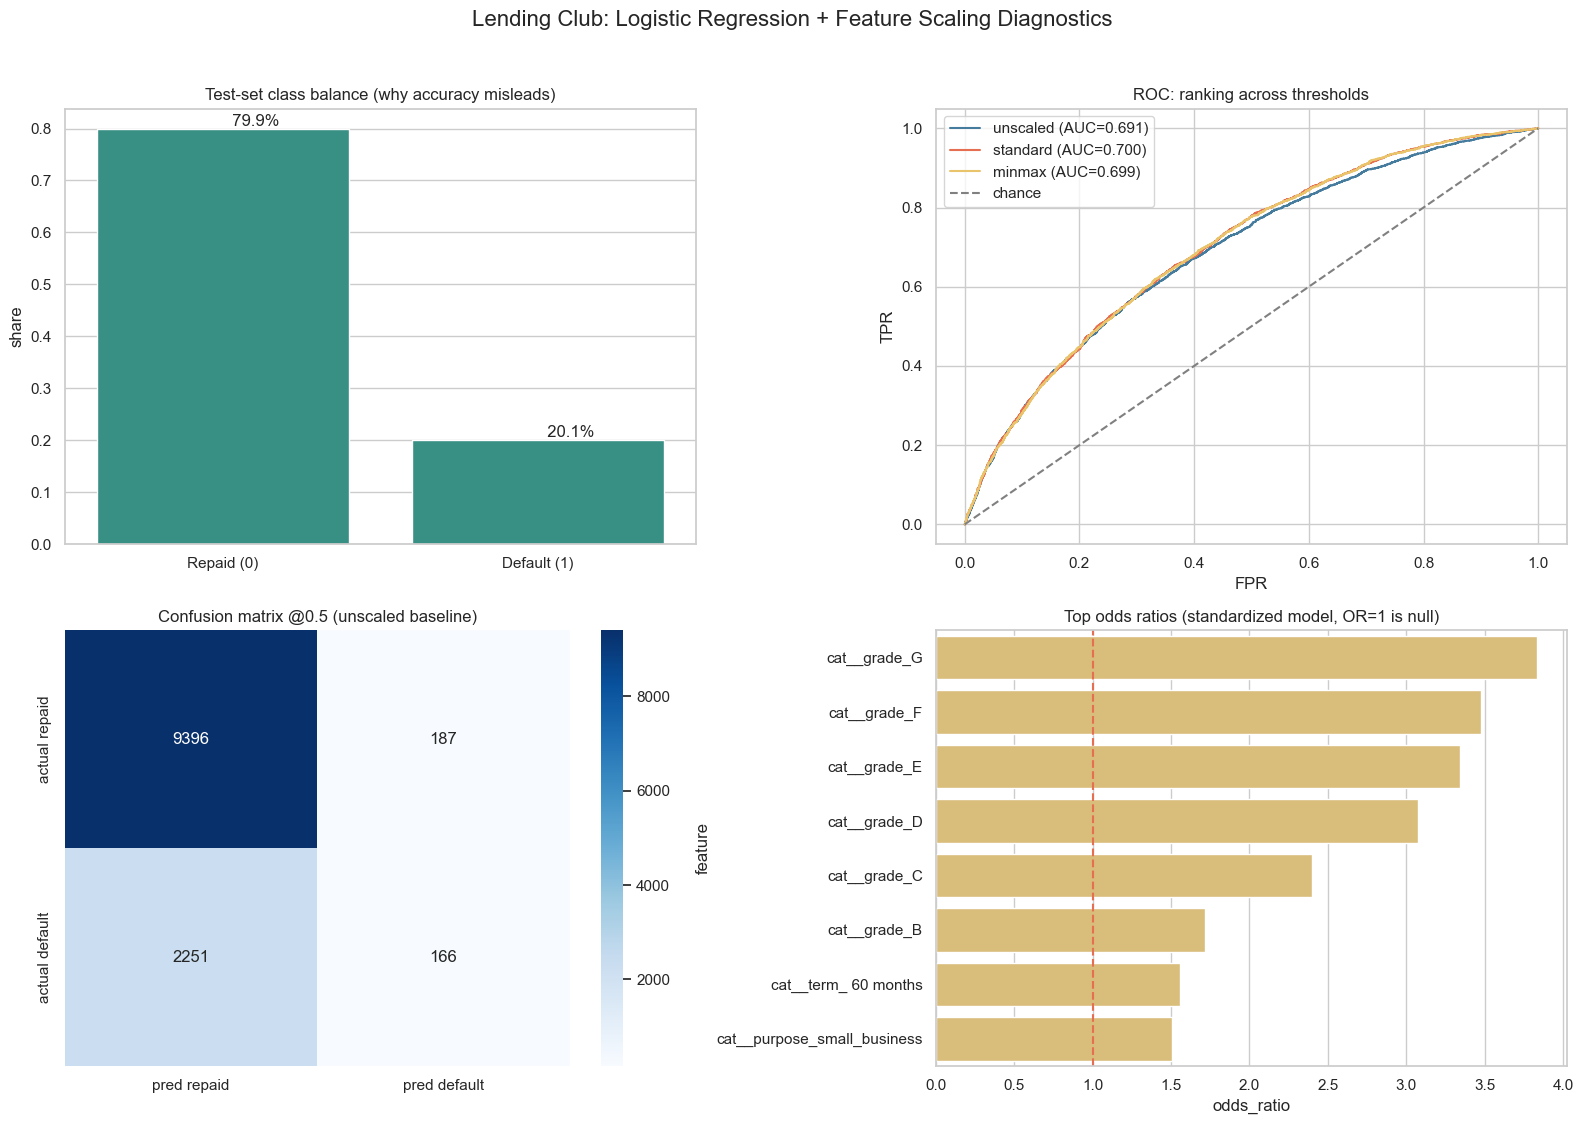


VISUAL INTERPRETATION GUIDE
- Class balance near 80/20: predicting all-repaid gives ~80% accuracy, so judge by precision/recall/F1/AUC.
- ROC curves: overlapping curves mean similar ranking; the scaling win here is convergence (n_iter), not AUC.
- Confusion matrix: low recall means most defaults are missed at 0.5 — threshold tuning or class_weight are follow-ups.
- Odds ratios: OR>1 = higher default odds holding others constant (association, not causation).


In [24]:
print("DATASET RESULTS")
print(f"Closed loans after cleaning: {len(df_model):,}")
print(f"Analysis sample: {len(dfs):,} (seed 42), train {len(X_train):,} / test {len(X_test):,}")
print(f"Default rate overall: {df_model['default'].mean():.2%}, test: {y_test.mean():.2%}")
print("\nMODEL RESULTS (test set)")
display(pd.DataFrame(results).T.round(4))
print(f"\nOptimizer iterations: {iters}")
print("(unscaled hitting max_iter=1000 means it did NOT converge; scaled converges in ~50-60.)")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Lending Club: Logistic Regression + Feature Scaling Diagnostics", fontsize=16, y=1.02)

# (a) class balance
ax = axes[0, 0]
sns.barplot(x=['Repaid (0)', 'Default (1)'], y=[1 - y_test.mean(), y_test.mean()], color="#2a9d8f", ax=ax)
ax.set_title("Test-set class balance (why accuracy misleads)")
ax.set_ylabel("share")
for i, v in enumerate([1 - y_test.mean(), y_test.mean()]):
    ax.text(i, v, f"  {v:.1%}", va="bottom")

# (b) ROC curves
ax = axes[0, 1]
for name, color in [('unscaled', '#457b9d'), ('standard', '#e76f51'), ('minmax', '#e9c46a')]:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    ax.plot(fpr, tpr, label=f"{name} (AUC={results[name]['roc_auc']:.3f})", color=color)
ax.plot([0, 1], [0, 1], '--', color='gray', label='chance')
ax.set_title("ROC: ranking across thresholds")
ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend()

# (c) confusion matrices at 0.5
ax = axes[1, 0]
base_test_prob = base_pipe.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, (base_test_prob >= THRESHOLD).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['pred repaid', 'pred default'], yticklabels=['actual repaid', 'actual default'])
ax.set_title(f"Confusion matrix @{THRESHOLD} (unscaled baseline)")

# (d) top odds ratios (standardized model)
ax = axes[1, 1]
top = odds.reindex(odds['odds_ratio'].sort_values(ascending=False).index[:8])
sns.barplot(x='odds_ratio', y='feature', data=top, color="#e9c46a", ax=ax)
ax.axvline(1, color="#e76f51", linestyle='--')
ax.set_title("Top odds ratios (standardized model, OR=1 is null)")

plt.tight_layout()
plt.show()

print("\nVISUAL INTERPRETATION GUIDE")
print("- Class balance near 80/20: predicting all-repaid gives ~80% accuracy, so judge by precision/recall/F1/AUC.")
print("- ROC curves: overlapping curves mean similar ranking; the scaling win here is convergence (n_iter), not AUC.")
print("- Confusion matrix: low recall means most defaults are missed at 0.5 — threshold tuning or class_weight are follow-ups.")
print("- Odds ratios: OR>1 = higher default odds holding others constant (association, not causation).")


## Conclusion
We asked: can loan data predict who will default? We used 60,000 closed Lending Club loans (about 20% defaulted).

What we found:
- Loan grade matters most. Grade G loans have roughly 4x the default odds of grade A loans. Lower grades mean riskier borrowers.
- Homeowners (mortgage or own) default less than others.
- Scaling the numbers (StandardScaler) made training about 18x faster (55 steps instead of 1000) but did not change accuracy much (AUC about 0.70).
- At the 0.50 cutoff the model is too careful: out of 2,417 real defaults it catches only 166 (about 1 in 15). It is good at ranking risky borrowers but bad at flagging them with this cutoff.

What this means for business: do not use 0.50 as-is. Lower the cutoff (for example 0.30) or balance the classes before saying yes or no to a loan.

Limit: this is one 60k sample with default settings, so it shows patterns (association), not proof of cause.
